In [11]:
import os
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')   # all paths below are from the repo root
# Run all 3 trained models on real photos in real/ and draw what they find.
# CNN can't find bricks itself -> brick box detector proposes boxes, CNN names each crop.
import csv, glob, cv2, numpy as np, torch, torchvision, matplotlib.pyplot as plt
from ultralytics import YOLO
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
DEV = 'cuda'
CLASSES = sorted({r['element_id'] for r in csv.DictReader(open('data/boxes.csv'))})
em = {r['element_id']: r for r in csv.DictReader(open('data/element_map.csv'))}
name = lambda c: f"{em[c]['part_num']} {em[c]['color']}"
IMGS = sorted(glob.glob('real/*.[jJpP][pPnN]*[gG]'))
assert IMGS, 'put photos (jpg/png) in real/'
CONF = 0.25

In [12]:
box = YOLO('runs/detect/runs/box/weights/best.pt')
yolo = YOLO('runs/cmp_yolo/weights/best.pt')
cnn = torchvision.models.resnet18(); cnn.fc = torch.nn.Linear(512, len(CLASSES))
cnn.load_state_dict(torch.load('models/cnn_resnet18.pt')); cnn = cnn.to(DEV).eval()
frcnn = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None, min_size=768, max_size=1024)
frcnn.roi_heads.box_predictor = FastRCNNPredictor(frcnn.roi_heads.box_predictor.cls_score.in_features, len(CLASSES) + 1)
frcnn.load_state_dict(torch.load('models/frcnn_r50.pt')); frcnn = frcnn.to(DEV).eval()
MEAN, STD = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1), torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

def run_cnn(img):  # img RGB
    out = []
    for x0, y0, x1, y1 in box.predict(img[..., ::-1], imgsz=1024, conf=CONF, verbose=False)[0].boxes.xyxy.cpu().numpy():
        s = max(x1 - x0, y1 - y0) * 1.15  # same square crop + 15% margin as training
        crop = cv2.resize(cv2.getRectSubPix(img, (int(s), int(s)), ((x0 + x1) / 2, (y0 + y1) / 2)), (224, 224))
        x = ((torch.from_numpy(crop).permute(2, 0, 1).float() / 255 - MEAN) / STD)[None].to(DEV)
        with torch.no_grad(): p = cnn(x).softmax(1)[0]
        out.append(((x0, y0, x1, y1), CLASSES[p.argmax()], p.max().item()))
    return out

def run_yolo(img):
    b = yolo.predict(img[..., ::-1], imgsz=1024, conf=CONF, verbose=False)[0].boxes.cpu()
    return [(tuple(xy), CLASSES[int(c)], float(s)) for xy, c, s in zip(b.xyxy.numpy(), b.cls, b.conf)]

def run_frcnn(img):
    x = torch.from_numpy(img).permute(2, 0, 1).float().div(255).to(DEV)
    with torch.no_grad(): o = frcnn([x])[0]
    return [(tuple(b.cpu().numpy()), CLASSES[int(l) - 1], float(s)) for b, l, s in zip(o['boxes'], o['labels'], o['scores']) if s >= CONF]

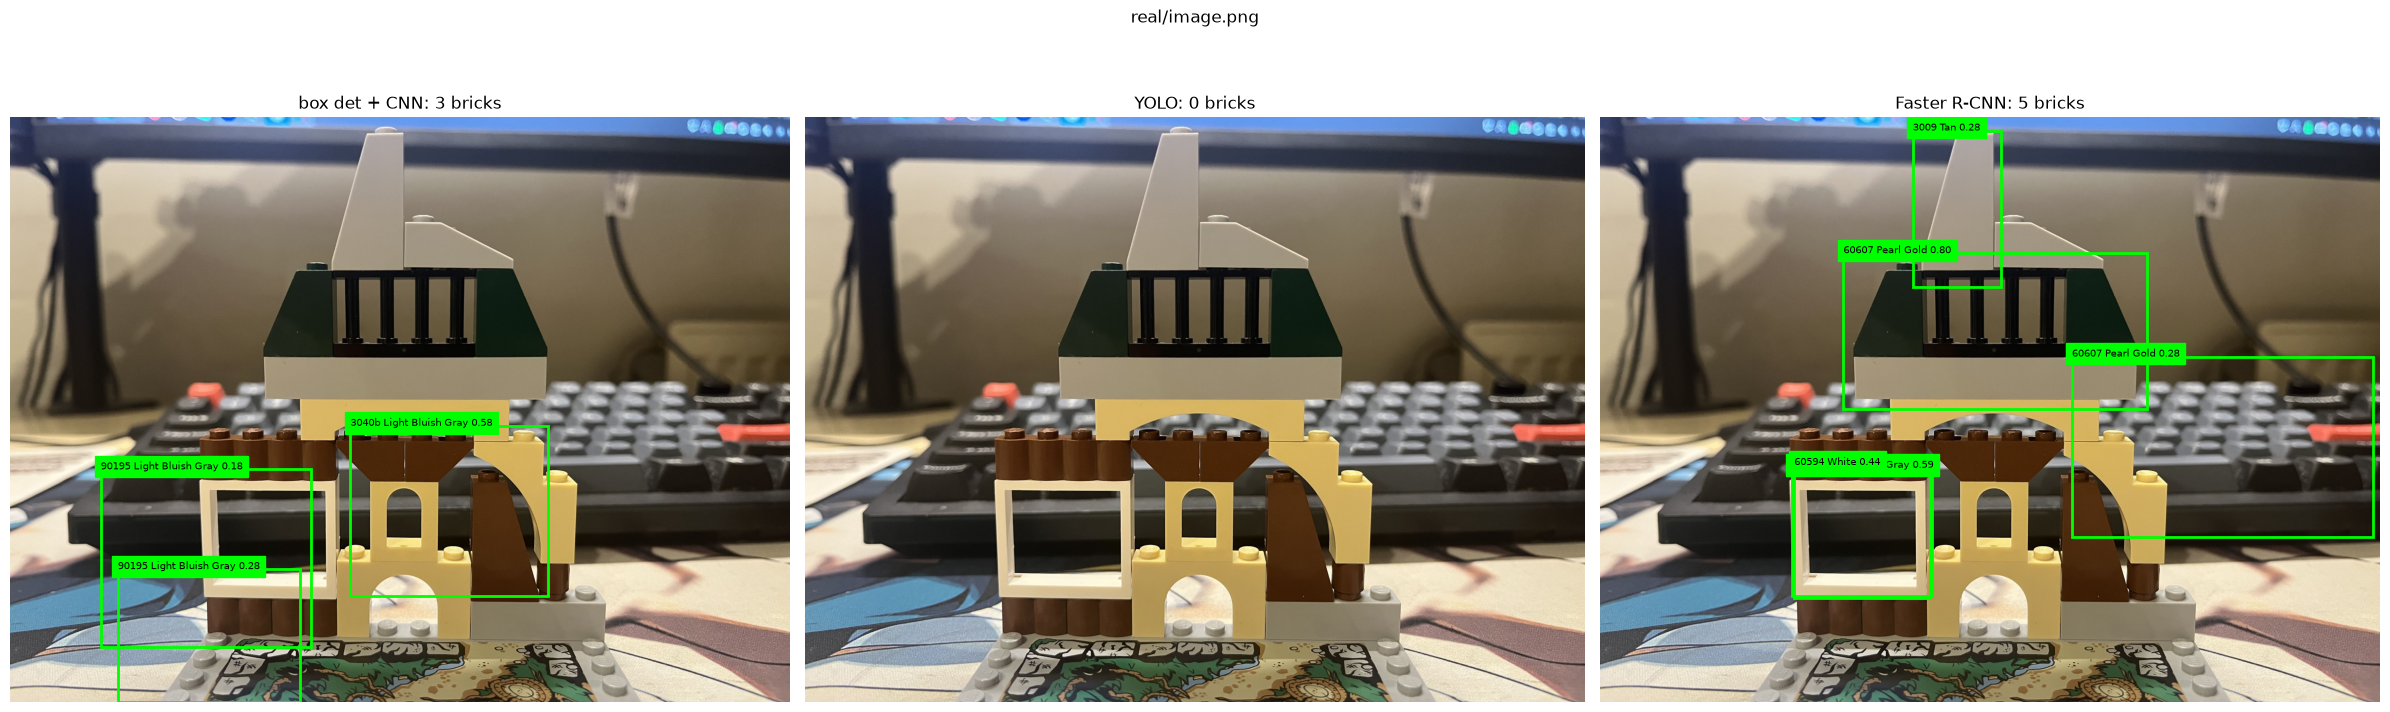

In [13]:
for f in IMGS:
    img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(1, 3, figsize=(24, 8))
    for a, (title, fn) in zip(ax, [('box det + CNN', run_cnn), ('YOLO', run_yolo), ('Faster R-CNN', run_frcnn)]):
        dets = fn(img); a.imshow(img); a.set_title(f'{title}: {len(dets)} bricks'); a.axis('off')
        for (x0, y0, x1, y1), c, s in dets:
            a.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color='lime', lw=2))
            a.text(x0, y0, f'{name(c)} {s:.2f}', color='black', fontsize=7, backgroundcolor='lime')
    fig.suptitle(f); plt.tight_layout(); plt.show()

In [14]:
# Stage 1 "find": slide tiles at several zoom levels so each brick looks as big as in training,
# run the detector per tile, map boxes back, merge duplicates.
# Stage 2 "focus": crop each found brick and let the CNN name it (it never sees the neighbours).
from torchvision.ops import nms
FRACS = (1/2, 1/3, 1/4)   # tile size as fraction of the short side; smaller = zoom in more
OVERLAP, EDGE = 0.3, 0.02  # drop boxes touching a tile cut (brick is cut off there, another tile sees it whole)

def tiles(img):
    H, W = img.shape[:2]
    for f in FRACS:
        s = int(min(H, W) * f); st = int(s * (1 - OVERLAP))
        for y in sorted({*range(0, H - s, st), H - s}):
            for x in sorted({*range(0, W - s, st), W - s}):
                yield x, y, s

def find_tiled(img, det=yolo):
    H, W = img.shape[:2]; B, S = [], []
    T = list(tiles(img))
    for i in range(0, len(T), 16):   # chunks keep memory flat
        chunk = T[i:i + 16]
        for (x, y, s), r in zip(chunk, det.predict([np.ascontiguousarray(img[y:y+s, x:x+s, ::-1]) for x, y, s in chunk], imgsz=640, conf=CONF, verbose=False)):
            for (a, b, c, d), sc in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()):
                e = EDGE * s
                if (a < e and x > 0) or (b < e and y > 0) or (c > s - e and x + s < W) or (d > s - e and y + s < H): continue
                B.append([a + x, b + y, c + x, d + y]); S.append(sc)
    if not B: return []
    B, S = torch.tensor(np.array(B)), torch.tensor(np.array(S))
    k = nms(B, S, 0.4)
    return [(tuple(B[i].numpy()), float(S[i])) for i in k]

def name_crops(img, found):
    out = []
    for (x0, y0, x1, y1), s0 in found:
        s = max(x1 - x0, y1 - y0) * 1.15
        crop = cv2.resize(cv2.getRectSubPix(img, (int(s), int(s)), ((x0 + x1) / 2, (y0 + y1) / 2)), (224, 224))
        x = ((torch.from_numpy(crop).permute(2, 0, 1).float() / 255 - MEAN) / STD)[None].to(DEV)
        with torch.no_grad(): p = cnn(x).softmax(1)[0]
        out.append(((x0, y0, x1, y1), CLASSES[p.argmax()], p.max().item()))
    return out

In [15]:
MIN_NAME = 0.5   # drop boxes the CNN can't name confidently (kills most background junk)
for f in IMGS:
    img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(1, 2, figsize=(20, 10))
    for a, (title, det) in zip(ax, [('tiled brick detector + CNN', box), ('tiled YOLO41 + CNN', yolo)]):
        dets = [d for d in name_crops(img, find_tiled(img, det)) if d[2] >= MIN_NAME]; a.imshow(img); a.set_title(f'{title}: {len(dets)} bricks'); a.axis('off')
        for (x0, y0, x1, y1), c, s in dets:
            a.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color='lime', lw=2))
            a.text(x0, y0, f'{name(c)} {s:.2f}', color='black', fontsize=7, backgroundcolor='lime')
    fig.suptitle(f); plt.tight_layout(); plt.show()

## Why the models fail on real towers

Measured on one real tower photo (`real/image.png`). Whole-photo detection gave about 5 junk boxes. Tiling plus the CNN confidence filter gave about 13 boxes, roughly half of them real bricks.

**1. Wrong scale.** In every training photo, one brick fills about a third of the frame. In a tower photo each brick is only a few percent of the frame. The detectors never saw small bricks. Tiling helps because it zooms in, but tiles also cut bricks in half.

**2. One brick per photo.** All 6491 training photos hold exactly one brick on a plain table. The models learned "find the single object". They never learned to separate bricks that touch, stack or hide each other. Even the separate 4541873 window parts were labeled as one box.

**3. Different background.** Training backgrounds were a plain table. Real photos have a monitor, a keyboard, a desk and a busy printed base plate. With no negative examples, studs on the base plate and desk corners look like bricks, and the CNN names them with high confidence (e.g. "98283 Sand Green 0.99").

**4. Hidden parts.** In a tower only the front of each brick is visible, and the top, sides and studs are covered. Training photos show whole bricks from above and from the side.

**5. Neighbours in the crop.** In a tower, the square crop the CNN gets includes the neighbouring bricks. Same-colour neighbours (tan on tan, brown on brown) blur where one brick ends and the next begins.

**6. No real test set.** Nothing scores the tower results, since there are no boxed tower photos. Every judgement above is by eye on a single image.

**What would fix it:** training data that looks like towers. Build synthetic scenes by cutting bricks out of the photos with the boxes we already have, pasting many at small scale onto busy backgrounds, and letting them overlap. The boxes come free. Add 10–20 hand-boxed real tower photos as the test set.